Total de ofertas crudas: 1289
Ofertas procesables (con descripción): 553


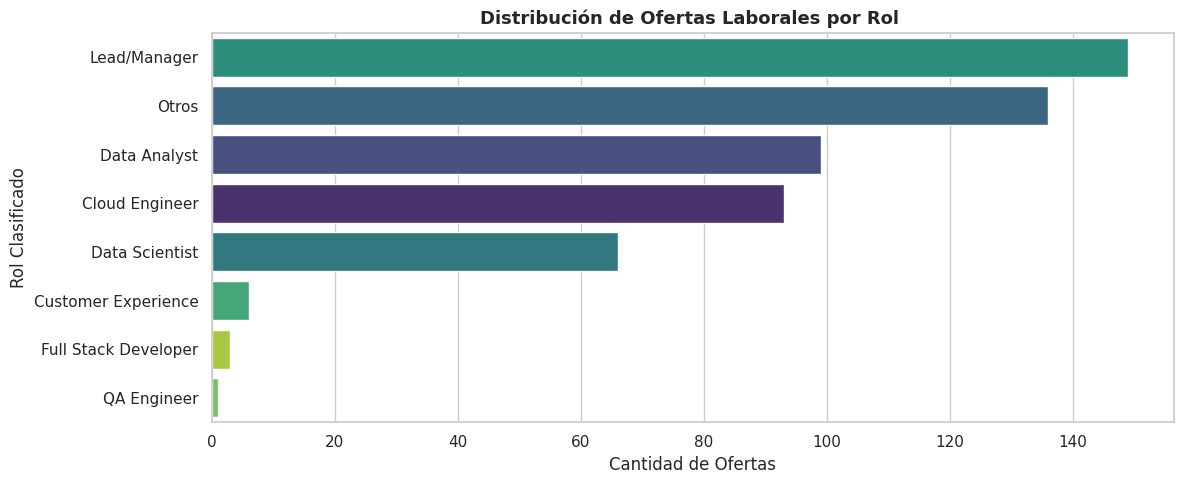

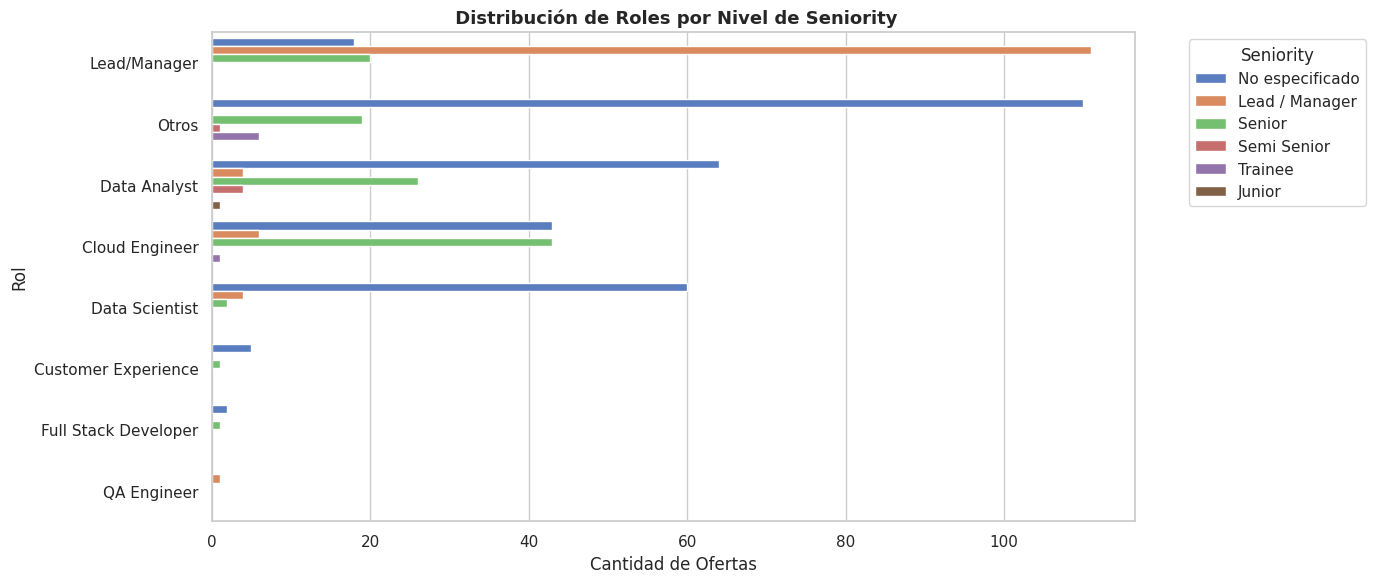

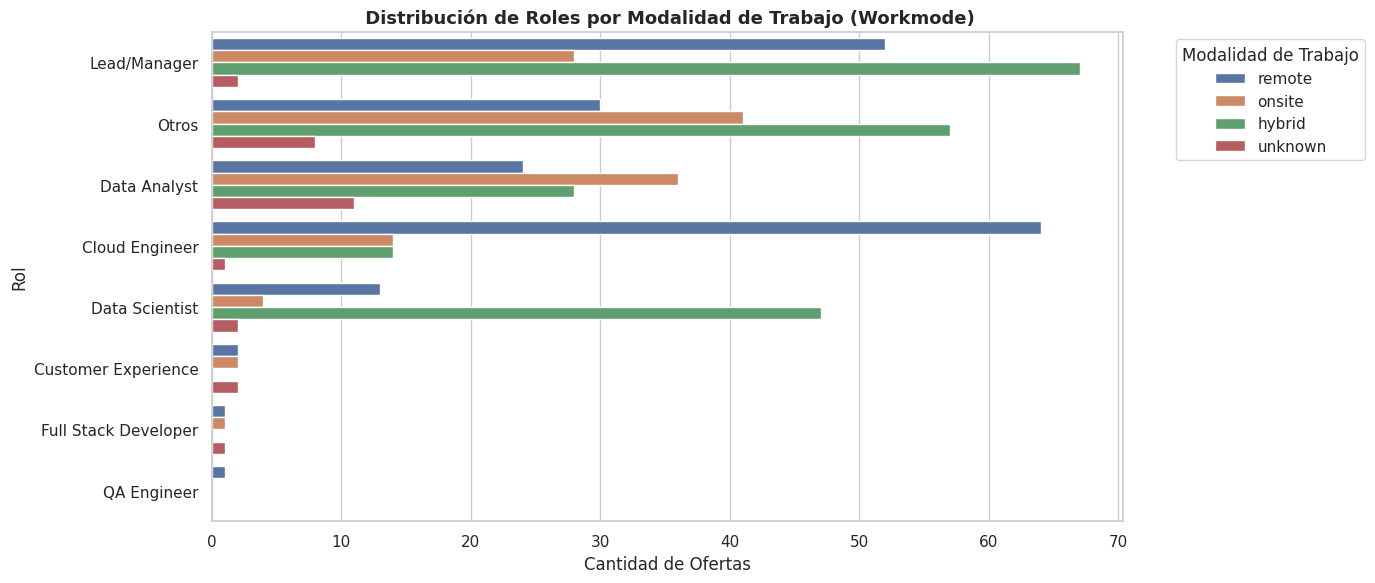

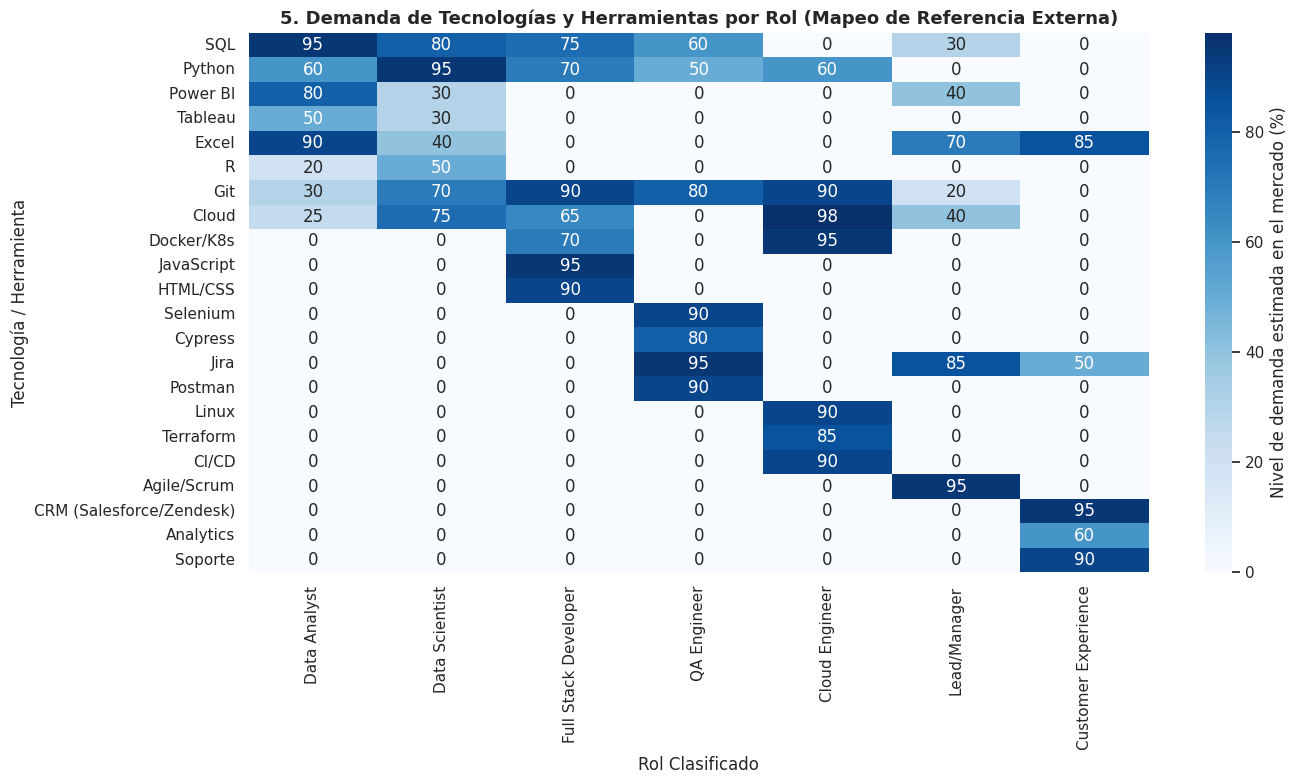

In [ ]:
import requests
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CARGA Y PREPARACIÓN DE LOS DATOS
# ==========================================
url = "https://api.apify.com/v2/key-value-stores/crearcode~latam-tech-jobs/records/latest"
response = requests.get(url)
response.raise_for_status()
data = response.json()

df = pd.json_normalize(data)
df = df.head(3000)
df.to_csv("./ofertas_laborales.csv", index=False, encoding="utf-8-sig")

# Filtrar registros con descripción válida
df_requisitos = df[
    df["description"].notna() &
    (df["description"].str.strip() != "")
].copy()

df_requisitos["title"] = df_requisitos["title"].fillna("").str.lower().str.strip()
df_requisitos["description"] = df_requisitos["description"].fillna("").str.lower().str.strip()
df_requisitos["texto_completo"] = df_requisitos["title"] + " " + df_requisitos["description"]

print(f"Total de ofertas crudas: {len(df)}")
print(f"Ofertas procesables (con descripción): {len(df_requisitos)}")

# ==========================================
# 2. CLASIFICACIÓN DE SENIORITY
# ==========================================
patrones_seniority = {
    "Trainee": r"\btrainee\b|\bintern(ship)?\b|\bestagi[aá]rio\b|\baprendiz\b",
    "Junior": r"\bjunior\b|\bjr\b|\bj[uú]nior\b",
    "Semi Senior": r"\bsemi[\s-]?senior\b|\bpleno\b|\bssr\b|\bmid[\s-]?level\b|\bmid[\s-]?senior\b",
    "Senior": r"\bsenior\b|\bsr\b|\bs[eê]nior\b",
    "Lead / Manager": r"\blead\b|\bmanager\b|\bl[ií]der\b|\bcoordenador\b|\bgerente\b"
}

def clasificar_seniority(texto):
    for nivel, patron in patrones_seniority.items():
        if re.search(patron, texto):
            return nivel
    return "No especificado"

df_requisitos["seniority"] = df_requisitos["texto_completo"].apply(clasificar_seniority)

# Estimación y extracción de años de experiencia
patrones_experiencia = [
    r"\b(\d{1,2})\s*\+?\s*(?:years?|yrs?)\b",
    r"\b(\d{1,2})\s*\+?\s*años?\b",
    r"\b(\d{1,2})\s*\+?\s*anos?\b"
]

def extraer_experiencia(texto):
    coincidencias = []
    for patron in patrones_experiencia:
        resultados = re.findall(patron, texto)
        coincidencias.extend(resultados)
    if coincidencias:
        return max(map(int, coincidencias))
    return np.nan

df_requisitos["años_experiencia"] = df_requisitos["texto_completo"].apply(extraer_experiencia)

equivalencias_experiencia = {
    "Trainee": "Menos de 1 año",
    "Junior": "1 a 2 años",
    "Semi Senior": "2 a 4 años",
    "Senior": "4 a 6 años",
    "Lead / Manager": "5 años o más"
}
df_requisitos["experiencia_estimada"] = df_requisitos["seniority"].map(equivalencias_experiencia)

# ==========================================
# 3. CLASIFICACIÓN DE ROLES
# ==========================================
patrones_roles = {
    "Data Analyst": r"\bdata\b|\bdatos\b|\banalysta?\b|\banalista\b|\bbussines\b|\banalisis\b|\banálisis\b|\bstrategic\b",
    "Data Scientist": r"\bdata\s+scientist\b|\bcientifico\s+de\s+datos\b|\bdata\s+science\b|\bgrowth\b|\bespecialista\b|\bexpert\b|\bprincipal\b",
    "Cloud Engineer": r"\bcloud\b|\bdevops\b|\baws\b|\bazure\b|\bgcp\b|\bsre\b|\binfrastructure\b|\bengineer\b",
    "Full Stack Developer": r"\bfull\s*stack\b|\bdeveloper\b|\bdesarrollador\b|\bprogramador\b|\bfrontend\b|\bbackend\b",
    "QA Engineer": r"\bqa\b|\bquality\s+assurance\b|\btesting\b|\banalista\s+de\s+calidad\b|\btest\b",
    "Lead/Manager": r"\blead\b|\bmanager\b|\blider\b|\bcoordenador\b|\bgerente\b|\bhead\b|\bdirector\b",
    "Customer Experience": r"\bcustomer\s+experience\b|\bcx\b|\bcustomer\s+success\b|\batencion\s+al\s+cliente\b|\bsupport\b|\bsoporte\b"
}

def clasificar_rol(titulo):
    if not isinstance(titulo, str):
        return "Otros"
    titulo_limpio = titulo.lower().strip()
    for rol, patron in patrones_roles.items():
        if re.search(patron, titulo_limpio):
            return rol
    return "Otros"

df_requisitos["rol_clasificado"] = df_requisitos["title"].apply(clasificar_rol)

# ==========================================
# 4. MAPEADO DE TECNOLOGÍAS EXTERNAS
# ==========================================
tecnologias_externas = {
    "Data Analyst": {"SQL": 95, "Python": 60, "Power BI": 80, "Tableau": 50, "Excel": 90, "R": 20, "Git": 30, "Cloud": 25},
    "Data Scientist": {"Python": 95, "SQL": 80, "R": 50, "Power BI": 30, "Tableau": 30, "Excel": 40, "Cloud": 75, "Git": 70},
    "Full Stack Developer": {"Python": 70, "SQL": 75, "Git": 90, "Cloud": 65, "Docker/K8s": 70, "JavaScript": 95, "HTML/CSS": 90},
    "QA Engineer": {"Python": 50, "Git": 80, "SQL": 60, "Selenium": 90, "Cypress": 80, "Jira": 95, "Postman": 90},
    "Cloud Engineer": {"Cloud": 98, "Docker/K8s": 95, "Git": 90, "Python": 60, "Linux": 90, "Terraform": 85, "CI/CD": 90},
    "Lead/Manager": {"Jira": 85, "Agile/Scrum": 95, "Power BI": 40, "Excel": 70, "SQL": 30, "Cloud": 40, "Git": 20},
    "Customer Experience": {"Excel": 85, "CRM (Salesforce/Zendesk)": 95, "Jira": 50, "Analytics": 60, "Soporte": 90}
}
df_tech_externo = pd.DataFrame(tecnologias_externas).fillna(0)

# ==========================================
# 5. GENERACIÓN DE TODOS LOS GRÁFICOS
# ==========================================
sns.set_theme(style="whitegrid")

# Gráfico 1: Distribución General de Roles
plt.figure(figsize=(12, 5))
sns.countplot(
    data=df_requisitos,
    y="rol_clasificado",
    order=df_requisitos["rol_clasificado"].value_counts().index,
    hue="rol_clasificado",
    legend=False,
    palette="viridis"
)
plt.title("Distribución de Ofertas Laborales por Rol ", fontsize=13, fontweight='bold')
plt.xlabel("Cantidad de Ofertas")
plt.ylabel("Rol Clasificado")
plt.tight_layout()
plt.show()



# Gráfico 3: Distribución de Roles por Nivel de Seniority
plt.figure(figsize=(14, 6))
sns.countplot(
    data=df_requisitos,
    y="rol_clasificado",
    hue="seniority",
    order=df_requisitos["rol_clasificado"].value_counts().index,
    palette="muted"
)
plt.title(" Distribución de Roles por Nivel de Seniority", fontsize=13, fontweight='bold')
plt.xlabel("Cantidad de Ofertas")
plt.ylabel("Rol")
plt.legend(title="Seniority", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Gráfico 4: Distribución de Roles por Modalidad de Trabajo (Workmode)
if 'workMode' in df_requisitos.columns:
    plt.figure(figsize=(14, 6))
    sns.countplot(
        data=df_requisitos,
        y="rol_clasificado",
        hue="workMode",
        order=df_requisitos["rol_clasificado"].value_counts().index,
        palette="deep"
    )
    plt.title(" Distribución de Roles por Modalidad de Trabajo (Workmode)", fontsize=13, fontweight='bold')
    plt.xlabel("Cantidad de Ofertas")
    plt.ylabel("Rol")
    plt.legend(title="Modalidad de Trabajo", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# Gráfico 5: Mapa de Calor de Tecnologías de Referencia por Rol
plt.figure(figsize=(14, 8))
sns.heatmap(
    df_tech_externo,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    cbar_kws={'label': 'Nivel de demanda estimada en el mercado (%)'}
)
plt.title("5. Demanda de Tecnologías y Herramientas por Rol (Mapeo de Referencia Externa)", fontsize=13, fontweight='bold')
plt.xlabel("Rol Clasificado", fontsize=12)
plt.ylabel("Tecnología / Herramienta", fontsize=12)
plt.tight_layout()
plt.show()